# Table of Contents
- [9.0 Introduction: interpolation vs fitting](#intro)
- [9.1 Linear interpolation](#linear)
- [9.2 Polynomial (Lagrange) interpolation](#lagrange)
- [9.3 Runge's phenomenon and Chebyshev nodes](#runge)
- [9.4 Cubic splines](#splines)
- [9.5 Least-squares fitting and $\chi^2$](#chi2)
- [9.6 Non-linear fitting with `scipy.optimize.curve_fit`](#curvefit)
- [9.7 Is the fit any good? Residuals and the bootstrap](#goodness)
- [Problems](#problems)

# 9.0 Introduction: interpolation vs fitting <a class="anchor" id="intro"></a>
We often know a function only at a set of points $(x_i, y_i)$ - from a table of physical constants, an expensive simulation, or an experiment. Two different questions arise:

- **Interpolation**: the data are *exact*. Find a smooth function that passes **through** every point, so we can estimate values in between.
- **Fitting (regression)**: the data are *noisy*. Find the parameters of a model that passes **close to** the points in a statistically meaningful way - and quote their uncertainties.

Confusing the two is one of the most common mistakes in undergraduate labs: never draw a wiggly curve through every noisy data point!

In [1]:
# BLOCK 9.0.1
import numpy as np
import matplotlib.pyplot as plt

# 9.1 Linear interpolation <a class="anchor" id="linear"></a>
Join the dots with straight lines. Between $x_i$ and $x_{i+1}$:

$$y(x) = y_i + (y_{i+1}-y_i)\frac{x - x_i}{x_{i+1}-x_i}.$$

(It's the same formula used for false position in Chapter 3.) The error is $\mathcal{O}(h^2)$, where $h$ is the spacing. `np.interp` does this for you - and is often all you need for a densely sampled table.

In [2]:
# BLOCK 9.1.1
# Density of water (kg/m^3) at a few temperatures (deg C)
T_tab = np.array([0, 10, 20, 30, 40, 50])
rho_tab = np.array([999.84, 999.70, 998.21, 995.65, 992.22, 988.03])
print(f'density at 25 C (linear interpolation): {np.interp(25, T_tab, rho_tab):.2f} kg/m^3 (table value 997.05)')

density at 25 C (linear interpolation): 996.93 kg/m^3 (table value 997.05)


# 9.2 Polynomial (Lagrange) interpolation <a class="anchor" id="lagrange"></a>
Through $n+1$ points there is exactly one polynomial of degree $n$. Lagrange wrote it down directly:

$$P(x) = \sum_{i=0}^{n} y_i\,\ell_i(x), \qquad \ell_i(x) = \prod_{j\neq i}\frac{x-x_j}{x_i-x_j}.$$

Each basis polynomial $\ell_i$ equals 1 at $x_i$ and 0 at every other node, so $P(x_i)=y_i$ automatically.

density at 25 C (Lagrange, degree 5): 997.05 kg/m^3


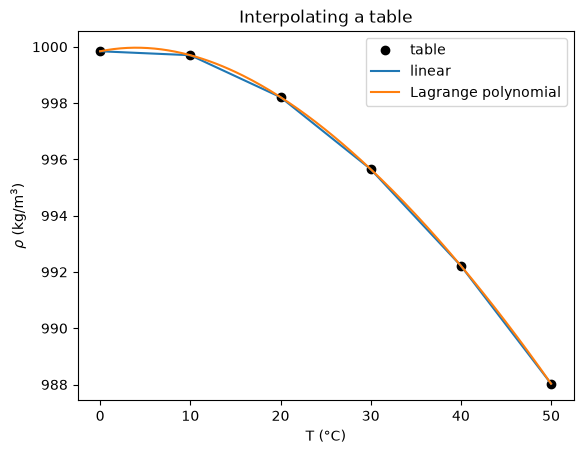

In [3]:
# BLOCK 9.2.1
def lagrange(x_nodes, y_nodes, x):
    x = np.asarray(x, dtype=float)
    P = np.zeros_like(x)
    for i in range(len(x_nodes)):
        ell = np.ones_like(x)
        for j in range(len(x_nodes)):
            if j != i:
                ell *= (x - x_nodes[j]) / (x_nodes[i] - x_nodes[j])
        P += y_nodes[i]*ell
    return P

print(f'density at 25 C (Lagrange, degree 5): {lagrange(T_tab, rho_tab, 25.0):.2f} kg/m^3')

T = np.linspace(0, 50, 200)
plt.plot(T_tab, rho_tab, 'ko', label='table')
plt.plot(T, np.interp(T, T_tab, rho_tab), label='linear')
plt.plot(T, lagrange(T_tab, rho_tab, T), label='Lagrange polynomial')
plt.xlabel('T (°C)'); plt.ylabel(r'$\rho$ (kg/m$^3$)'); plt.legend(); plt.title('Interpolating a table')
plt.show()

# 9.3 Runge's phenomenon and Chebyshev nodes <a class="anchor" id="runge"></a>
More points, higher degree, better answer? **No!** Try interpolating the innocent function $f(x)=1/(1+25x^2)$ on equally-spaced points.

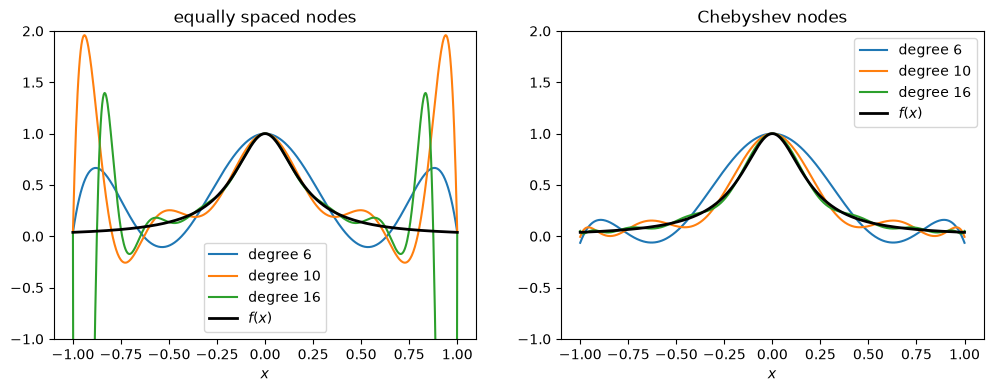

In [4]:
# BLOCK 9.3.1
runge = lambda x: 1/(1 + 25*x**2)
x = np.linspace(-1, 1, 500)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for n in [6, 10, 16]:
    xe = np.linspace(-1, 1, n + 1)
    xc = np.cos((2*np.arange(n + 1) + 1)*np.pi/(2*(n + 1)))     # Chebyshev nodes
    axes[0].plot(x, lagrange(xe, runge(xe), x), label=f'degree {n}')
    axes[1].plot(x, lagrange(xc, runge(xc), x), label=f'degree {n}')
for ax, title in zip(axes, ['equally spaced nodes', 'Chebyshev nodes']):
    ax.plot(x, runge(x), 'k', lw=2, label='$f(x)$')
    ax.set_ylim(-1, 2); ax.set_title(title); ax.legend(); ax.set_xlabel('$x$')
plt.show()

With equal spacing the polynomial oscillates wildly near the ends, and gets *worse* as the degree increases. The cure is to cluster the nodes towards the ends: the **Chebyshev nodes** $x_k=\cos\left(\frac{(2k+1)\pi}{2(n+1)}\right)$ - projections of equally spaced points on a semicircle - make the interpolation converge beautifully.

**Lesson:** avoid high-degree polynomials through equally spaced data. Use piecewise methods instead...

# 9.4 Cubic splines <a class="anchor" id="splines"></a>
A **cubic spline** uses a different cubic polynomial on each interval, glued together so that the value, slope **and curvature** are continuous at every node. (The name comes from the flexible strips of wood that draughtsmen bent through pegs to draw smooth curves for ship hulls.) It is smooth, local and doesn't oscillate - the default choice for interpolation.

Requiring continuity of $y''$ at each interior node gives a **tridiagonal** system (Chapter 6 again!) for the second derivatives $M_i = y''(x_i)$:

$$h_{i-1}M_{i-1} + 2(h_{i-1}+h_i)M_i + h_i M_{i+1} = 6\left(\frac{y_{i+1}-y_i}{h_i} - \frac{y_i - y_{i-1}}{h_{i-1}}\right),$$

with $M_0=M_n=0$ for a "natural" spline. Here's a from-scratch version followed by scipy's.

our spline matches scipy? True


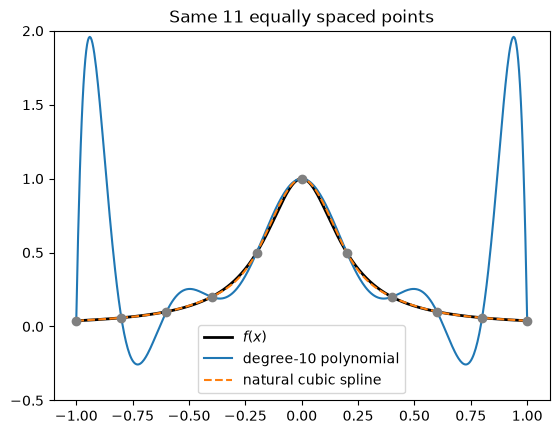

In [5]:
# BLOCK 9.4.1
from scipy import linalg
from scipy.interpolate import CubicSpline

def natural_spline(xn, yn):
    n = len(xn) - 1
    h = np.diff(xn)
    # build the tridiagonal system for the interior M_1 ... M_{n-1}
    ab = np.zeros((3, n - 1))
    ab[0, 1:] = h[1:-1]
    ab[1, :] = 2*(h[:-1] + h[1:])
    ab[2, :-1] = h[1:-1]
    rhs = 6*(np.diff(yn)[1:]/h[1:] - np.diff(yn)[:-1]/h[:-1])
    M = np.zeros(n + 1)
    M[1:-1] = linalg.solve_banded((1, 1), ab, rhs)

    def S(x):
        i = np.clip(np.searchsorted(xn, x) - 1, 0, n - 1)
        dx1, dx2 = x - xn[i], xn[i+1] - x
        return (M[i]*dx2**3 + M[i+1]*dx1**3)/(6*h[i]) \
             + (yn[i]/h[i] - M[i]*h[i]/6)*dx2 + (yn[i+1]/h[i] - M[i+1]*h[i]/6)*dx1
    return S

xe = np.linspace(-1, 1, 11)
S = natural_spline(xe, runge(xe))
cs = CubicSpline(xe, runge(xe), bc_type='natural')
print('our spline matches scipy?', np.allclose(S(x), cs(x)))

plt.plot(x, runge(x), 'k', lw=2, label='$f(x)$')
plt.plot(x, lagrange(xe, runge(xe), x), label='degree-10 polynomial')
plt.plot(x, S(x), '--', label='natural cubic spline')
plt.plot(xe, runge(xe), 'o', color='grey')
plt.ylim(-0.5, 2); plt.legend(); plt.title('Same 11 equally spaced points'); plt.show()

# 9.5 Least-squares fitting and $\chi^2$ <a class="anchor" id="chi2"></a>
Now the data are noisy: $y_i \pm \sigma_i$. We want the parameters $\boldsymbol\theta$ of a model $f(x;\boldsymbol\theta)$ that make the data most probable. If the errors are Gaussian, this is equivalent to minimising

$$\chi^2(\boldsymbol\theta) = \sum_i\left(\frac{y_i - f(x_i;\boldsymbol\theta)}{\sigma_i}\right)^2.$$

For a model that is **linear in the parameters**, e.g. $f = a + bx + cx^2$ (linear in $a,b,c$ even though not in $x$!), minimising $\chi^2$ is a linear least-squares problem (Chapter 6.9). Writing $A_{ij} = \phi_j(x_i)/\sigma_i$ for basis functions $\phi_j$ and $b_i = y_i/\sigma_i$, the best-fit parameters solve $A^TA\boldsymbol\theta = A^T\mathbf b$, and their **covariance matrix** is $C = (A^TA)^{-1}$. The parameter uncertainties are $\sqrt{C_{jj}}$.

**Example:** measuring $g$ by timing a falling object. $y = y_0 + v_0t - \tfrac12 g t^2$.

In [6]:
# BLOCK 9.5.1
rng = np.random.default_rng(7)
t = np.linspace(0.05, 0.6, 12)
sigma = 0.004*np.ones_like(t)                         # 4 mm position uncertainty
y = 1.2 + 0.3*t - 0.5*9.81*t**2 + rng.normal(0, sigma)

A = np.column_stack([np.ones_like(t), t, t**2]) / sigma[:, None]
theta, *_ = np.linalg.lstsq(A, y/sigma, rcond=None)
cov = np.linalg.inv(A.T @ A)
err = np.sqrt(np.diag(cov))

g_fit, g_err = -2*theta[2], 2*err[2]
chi2 = np.sum(((y - (theta[0] + theta[1]*t + theta[2]*t**2))/sigma)**2)
dof = len(t) - 3
print(f'g = {g_fit:.3f} ± {g_err:.3f} m/s^2')
print(f'chi^2 = {chi2:.2f} for {dof} degrees of freedom (reduced chi^2 = {chi2/dof:.2f})')

g = 9.755 ± 0.088 m/s^2
chi^2 = 4.19 for 9 degrees of freedom (reduced chi^2 = 0.47)


The **reduced chi-squared** $\chi^2_\nu = \chi^2/\nu$ (with $\nu$ = number of points minus number of parameters) should be about 1 for a good fit:
- $\chi^2_\nu \gg 1$: the model is wrong, or you underestimated your errors.
- $\chi^2_\nu \ll 1$: you overestimated your errors (or are fitting noise).

# 9.6 Non-linear fitting with `scipy.optimize.curve_fit` <a class="anchor" id="curvefit"></a>
Most physical models are non-linear in their parameters: exponential decays, Lorentzian or Gaussian peaks, damped oscillations. Then $\chi^2$ must be minimised iteratively (the Levenberg-Marquardt algorithm, which blends Newton's method with gradient descent). `curve_fit` does all the work, but:

1. **Always pass `sigma=` and `absolute_sigma=True`** if you know your errors - otherwise the uncertainties are rescaled.
2. **Give good starting guesses `p0`** - non-linear fits can get stuck in local minima.

**Example:** a radioactive source with background. Counts per 10 s in a Geiger counter: $N(t) = N_0 e^{-t/\tau} + B$. Counting statistics are Poisson, so $\sigma_i\approx\sqrt{N_i}$.

 N0 =   495.34 ± 13.74
tau =   117.17 ± 4.69
  B =    32.11 ± 2.67
half-life = 81.2 ± 3.3 s


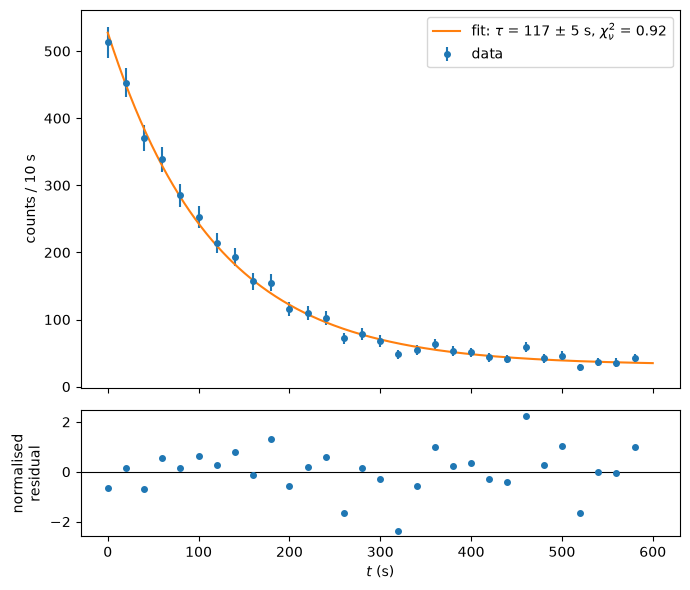

In [7]:
# BLOCK 9.6.1
from scipy.optimize import curve_fit

def decay_model(t, N0, tau, B):
    return N0*np.exp(-t/tau) + B

t = np.arange(0, 600, 20.0)                            # seconds
counts = rng.poisson(decay_model(t, 500, 120, 30))     # true tau = 120 s
sig = np.sqrt(np.maximum(counts, 1))

popt, pcov = curve_fit(decay_model, t, counts, p0=[400, 100, 10], sigma=sig, absolute_sigma=True)
perr = np.sqrt(np.diag(pcov))
for name, val, e in zip(['N0', 'tau', 'B'], popt, perr):
    print(f'{name:>3} = {val:8.2f} ± {e:.2f}')
print(f'half-life = {popt[1]*np.log(2):.1f} ± {perr[1]*np.log(2):.1f} s')

residuals = (counts - decay_model(t, *popt))/sig
chi2_nu = np.sum(residuals**2)/(len(t) - 3)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
ax1.errorbar(t, counts, sig, fmt='o', ms=4, label='data')
tt = np.linspace(0, 600, 300)
ax1.plot(tt, decay_model(tt, *popt), label=fr'fit: $\tau$ = {popt[1]:.0f} ± {perr[1]:.0f} s, $\chi^2_\nu$ = {chi2_nu:.2f}')
ax1.set_ylabel('counts / 10 s'); ax1.legend()
ax2.axhline(0, color='k', lw=0.8); ax2.plot(t, residuals, 'o', ms=4)
ax2.set_xlabel('$t$ (s)'); ax2.set_ylabel('normalised\nresidual')
plt.tight_layout(); plt.show()

# 9.7 Is the fit any good? Residuals and the bootstrap <a class="anchor" id="goodness"></a>
A good fit has **normalised residuals** $(y_i - f_i)/\sigma_i$ that scatter randomly around zero with unit spread - no trends, no curvature. A systematic pattern means the model is missing some physics.

The covariance matrix from `curve_fit` assumes the $\chi^2$ surface is a nice parabola near the minimum. A robust, assumption-light alternative is the **bootstrap**: create many fake datasets by *resampling the data points with replacement*, refit each one, and look at the spread of the fitted parameters. It's a Monte Carlo method (Chapter 10) and works for almost any statistic.

bootstrap: tau = 116.7 ± 4.6 s  (curve_fit said ± 4.7 s)


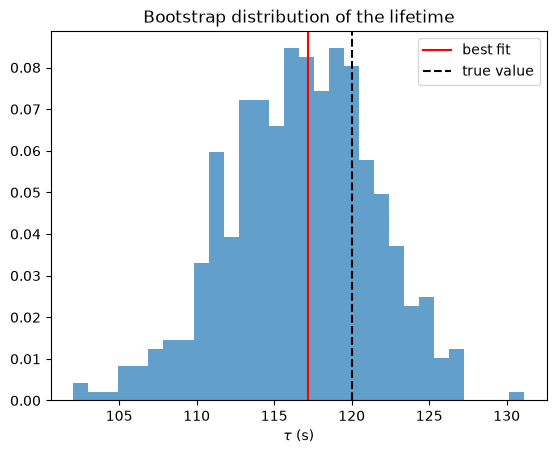

In [8]:
# BLOCK 9.7.1
taus = []
for _ in range(500):
    idx = rng.integers(0, len(t), len(t))              # resample with replacement
    try:
        p, _ = curve_fit(decay_model, t[idx], counts[idx], p0=popt, sigma=sig[idx], maxfev=2000)
        taus.append(p[1])
    except RuntimeError:
        pass                                           # occasionally a resample won't fit
taus = np.array(taus)
print(f'bootstrap: tau = {np.mean(taus):.1f} ± {np.std(taus):.1f} s  (curve_fit said ± {perr[1]:.1f} s)')

plt.hist(taus, bins=30, density=True, alpha=0.7)
plt.axvline(popt[1], color='r', label='best fit'); plt.axvline(120, color='k', ls='--', label='true value')
plt.xlabel(r'$\tau$ (s)'); plt.legend(); plt.title('Bootstrap distribution of the lifetime'); plt.show()

# Problems <a class="anchor" id="problems"></a>

### Exercise 1 - Interpolation error
Interpolate $\sin x$ on $[0,\pi]$ with $n$ equally-spaced points using `np.interp` and `CubicSpline`. Plot the maximum error against $n$ on log-log axes and measure the order of each method.

### Exercise 2 - Hubble's law
Using a table of galaxy distances $d$ (Mpc) and recession velocities $v$ (km/s) with uncertainties (e.g. Hubble's original 1929 data, or modern Cepheid data), fit $v=H_0d$ and find $H_0$ with its uncertainty. Estimate the age of the Universe $1/H_0$ in Gyr.

### Exercise 3 - A resonance curve
Simulate noisy measurements of a Lorentzian $A(\omega)=\dfrac{A_0}{\sqrt{(\omega_0^2-\omega^2)^2+\gamma^2\omega^2}}$ and fit for $\omega_0$ and $\gamma$. What happens if your starting guess for $\omega_0$ is far from the truth?

### Exercise 4 - Choosing a model
Fit polynomials of degree 1 to 8 to the falling-object data in BLOCK 9.5.1. Plot $\chi^2_\nu$ against degree. Which model would you choose and why? (Look up the *Akaike information criterion* for a more principled answer.)

In [9]:
# Start working here